<a href="https://colab.research.google.com/github/guslimaa777/45419370/blob/main/aula10_avaliacao_modelos_aluno_revisado_generalizacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 10 – Fundamentos de avaliação: generalização, overfitting e divisão de dados

## Versão do aluno

### Objetivo da aula
Montar um experimento de avaliação de modelos e interpretar como a divisão dos dados influencia a confiabilidade das previsões.

### Instruções
Complete as células indicadas e registre suas interpretações.  
Use gráficos para comparar os resultados.


#Generalização
> é quando o modelo consegue usar o que aprendeu para fazer boas previsões em dados que nunca viu antes.

## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura e manipulação da base;
- visualização;
- divisão dos dados;
- pipeline de pré-processamento;
- regressão e métricas;
- validação cruzada.


In [ ]:
# Importe a biblioteca `pandas` utilizando o alias `pd` para manipulação de tabelas e DataFrames.

# Importe a biblioteca `numpy` utilizando o alias `np` para operações matemáticas e numéricas.

# Importe o módulo `matplotlib.pyplot` utilizando o alias `plt` para criação de gráficos.

# Importe `train_test_split` do módulo `sklearn.model_selection` para dividir os dados
# em conjuntos de treinamento e validação.
# Importe `cross_val_score` para realizar validação cruzada e avaliar o modelo.
# Importe `KFold` para definir como os dados serão divididos durante a validação cruzada.

# Importe `ColumnTransformer` do módulo `sklearn.compose` para aplicar diferentes
# tratamentos às diferentes colunas do dataset.

# Importe `Pipeline` do módulo `sklearn.pipeline` para organizar as etapas
# de pré-processamento e modelagem em uma sequência.

# Importe `OneHotEncoder` do módulo `sklearn.preprocessing` para transformar
# variáveis categóricas em variáveis numéricas utilizando codificação One-Hot.

# Importe `StandardScaler` do módulo `sklearn.preprocessing` para padronizar
# variáveis numéricas, colocando-as em uma escala comparável.

# Importe `SimpleImputer` do módulo `sklearn.impute` para tratar valores ausentes
# preenchendo os dados faltantes de acordo com uma estratégia definida.

# Importe `LinearRegression` do módulo `sklearn.linear_model`
# para criar um modelo de Regressão Linear.

# Importe `DecisionTreeRegressor` do módulo `sklearn.tree`
# para criar um modelo de Árvore de Decisão para prever valores numéricos.

# Importe `mean_absolute_error` do módulo `sklearn.metrics`
# para calcular o MAE, que representa o erro absoluto médio das previsões.

# Importe `mean_squared_error` do módulo `sklearn.metrics`
# para calcular o MSE, que representa a média dos erros ao quadrado.

# Importe `r2_score` do módulo `sklearn.metrics`
# para calcular o R², que indica quanto da variação do valor real
# é explicada pelo modelo.

In [2]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Leitura da base

Leia o arquivo `dados_aula10_avaliacao_modelos_industrial.csv` e mostre as primeiras linhas.


In [4]:
# Complete aqui
df = pd.read_csv('dados_aula10_avaliacao_modelos_industrial.csv')
df.head()

,id_registro,linha,turno,produto,temperatura_c,pressao_bar,vibracao_mm_s,abertura_valvula_pct,consumo_energia_kwh,tempo_resposta_s,leituras_invalidas,horas_operacao_bomba,vazao_real_l_min
0,AVL_0001,Linha_A,Noite,Acido,NaN,3.50,2.57,69.48,21.58,1.97,2,228.0,69.21
1,AVL_0002,Linha_B,Tarde,Acido,34.58,4.60,2.60,41.92,23.34,3.15,5,366.2,53.74
2,AVL_0003,Linha_C,Manhã,Solvente,52.54,2.84,2.86,49.19,24.31,3.23,1,326.8,38.23
3,AVL_0004,Linha_A,Manhã,Base,57.71,3.46,2.67,56.41,25.81,0.51,3,392.5,50.74
4,AVL_0005,Linha_B,Noite,Base,43.61,4.63,2.55,49.88,23.25,2.41,2,215.4,57.10


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas.


In [ ]:
# Exiba a dimensão do DataFrame `df` utilizando `df.shape`.
# O resultado mostra a quantidade de linhas e colunas da base.

# Exiba o texto `Tipos de dados:` utilizando `print()`.
# O caractere `\n` cria uma linha em branco antes do texto para organizar a visualização.

# Exiba os tipos de dados de todas as colunas utilizando `df.dtypes`.
# Essa informação permite identificar se cada coluna é numérica, texto, data, entre outros tipos.

# Exiba o texto `Valores faltantes:` utilizando `print()`.
# Utilize `\n` para criar uma linha em branco antes do texto.

# Conte os valores ausentes de cada coluna utilizando `df.isna().sum()`.
# `isna()` identifica os valores ausentes e `sum()` contabiliza quantos existem em cada coluna.

# Conte as linhas duplicadas utilizando `df.duplicated().sum()`.
# `duplicated()` identifica registros duplicados e `sum()` contabiliza a quantidade total.

In [6]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:', df.duplicated().sum())

Dimensão da base: (332, 13)

Tipos de dados:
id_registro              object
linha                    object
turno                    object
produto                  object
temperatura_c           float64
pressao_bar             float64
vibracao_mm_s           float64
abertura_valvula_pct    float64
consumo_energia_kwh     float64
tempo_resposta_s        float64
leituras_invalidas        int64
horas_operacao_bomba    float64
vazao_real_l_min        float64
dtype: object

Valores faltantes:
id_registro             0
linha                   0
turno                   0
produto                 7
temperatura_c           7
pressao_bar             8
vibracao_mm_s           0
abertura_valvula_pct    0
consumo_energia_kwh     0
tempo_resposta_s        9
leituras_invalidas      0
horas_operacao_bomba    0
vazao_real_l_min        0
dtype: int64

Duplicatas: 12


**Registro do aluno:**  
-  
-  


## 4. Limpeza básica

Remova as duplicatas da base.


In [7]:
# Remova as linhas duplicadas do DataFrame `df` utilizando `drop_duplicates()`.

# Utilize `copy()` para criar uma cópia independente do DataFrame após a remoção das duplicatas.
# Armazene o resultado novamente na variável `df`.

# Exiba a nova dimensão da base utilizando `print()` e `df.shape`.
# A mensagem exibida deve ser: 'Dimensão após remoção de duplicatas:'.
# `df.shape` mostra a quantidade de linhas e colunas após a limpeza.

In [9]:
# Complete aqui
df = df.drop_duplicates().copy()
print(df.shape)

(320, 13)


## 5. Definição de X e y

Separe:
- `X`: variáveis de entrada;
- `y`: variável-alvo `vazao_real_l_min`.

**Pergunta:** por que `id_registro` não deve ser usado como preditora?


In [10]:
# Crie a variável `X` contendo as variáveis de entrada do modelo.
# Utilize `df.drop()` para remover as colunas que não serão utilizadas como entrada.
# Remova `id_registro`, pois é apenas um identificador do registro.
# Remova `vazao_real_l_min`, pois essa será a variável que o modelo deverá prever.
# Utilize `columns=[...]` para informar as colunas que serão removidas.

# Crie a variável `y` contendo a variável que o modelo deverá prever.
# Selecione a coluna `vazao_real_l_min` do DataFrame `df`.

# Opcionalmente, utilize `print(X)` para visualizar as variáveis de entrada.
# O comando pode permanecer comentado para não exibir toda a tabela.

# Exiba a dimensão de `X` utilizando `X.shape`.
# `X.shape` mostra a quantidade de registros e de variáveis utilizadas como entrada.

# Exiba a dimensão de `y` utilizando `y.shape`.
# `y.shape` mostra a quantidade de registros da variável que será prevista.

In [13]:
# Complete aqui
X = df.drop(columns=['id_registro', 'vazao_real_l_min'])
y = df['vazao_real_l_min']

print(X.shape)
print(y.shape)

(320, 11)
(320,)


**Resposta do aluno:**  


## 6. Divisão em treino, validação e teste

Faça a divisão em duas etapas:
1. treino+validação e teste;
2. treino e validação.


In [51]:
# Divida os dados em dois conjuntos utilizando `train_test_split()`.
# Separe `X` e `y` em uma parte temporária (`X_temp` e `y_temp`) e uma parte de teste (`X_test` e `y_test`).
# Utilize `test_size=0.2` para reservar 20% dos dados para o conjunto de teste.
# Utilize `random_state=42` para garantir que a divisão seja reproduzível.

# Divida novamente os dados temporários utilizando `train_test_split()`.
# Separe `X_temp` e `y_temp` em conjunto de treinamento (`X_train` e `y_train`)
# e conjunto de validação (`X_val` e `y_val`).
# Utilize `test_size=0.25` para reservar 25% dos dados temporários para validação.
# Utilize `random_state=42` para manter a divisão reproduzível.

# Ao final, os dados ficam aproximadamente distribuídos em:
# 60% para treinamento, 20% para validação e 20% para teste.

In [31]:
# Complete aqui
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42
)

print('Treino:', X_train.shape, y_train.shape)
print('Validação:', X_val.shape, y_val.shape)
print('Teste:', X_test.shape, y_test.shape)

Treino: (192, 11) (192,)
Validação: (64, 11) (64,)
Teste: (64, 11) (64,)


**Resposta do aluno:**  
- Treino:  
- Validação:  
- Teste:  


## 7. Pré-processamento com pipeline

Monte um pipeline com:
- imputação da mediana + padronização para numéricas;
- imputação da moda + one-hot encoding para categóricas.


In [50]:
# Identifique as colunas numéricas de `X` utilizando `select_dtypes()`.
# Utilize `include=['int64', 'float64']` para selecionar colunas dos tipos inteiro e decimal.
# Utilize `.columns` para obter os nomes das colunas selecionadas.
# Utilize `.tolist()` para transformar os nomes das colunas em uma lista.
# Armazene o resultado na variável `colunas_numericas`.

# Identifique as colunas categóricas de `X` utilizando `select_dtypes()`.
# Utilize `include=['object']` para selecionar as colunas que armazenam textos/categorias.
# Utilize `.columns` e `.tolist()` para obter os nomes dessas colunas em formato de lista.
# Armazene o resultado na variável `colunas_categoricas`.

# Crie o pipeline `transformador_numerico` utilizando `Pipeline(steps=[...])`.
# Na primeira etapa, utilize `SimpleImputer(strategy='median')` para preencher valores ausentes
# das colunas numéricas utilizando a mediana.
# Na segunda etapa, utilize `StandardScaler()` para padronizar as variáveis numéricas.

# Crie o pipeline `transformador_categorico` utilizando `Pipeline(steps=[...])`.
# Na primeira etapa, utilize `SimpleImputer(strategy='most_frequent')` para preencher valores ausentes
# das colunas categóricas utilizando o valor mais frequente.
# Na segunda etapa, utilize `OneHotEncoder(handle_unknown='ignore')` para transformar categorias em números.
# O parâmetro `handle_unknown='ignore'` permite que o modelo encontre categorias novas
# que não apareceram durante o treinamento sem gerar erro.

# Crie o `preprocessador` utilizando `ColumnTransformer(transformers=[...])`.
# Configure o transformador `num` para aplicar `transformador_numerico` às `colunas_numericas`.
# Configure o transformador `cat` para aplicar `transformador_categorico` às `colunas_categoricas`.

# Ao final, escreva `colunas_numericas` e `colunas_categoricas` para visualizar
# quais colunas foram identificadas como numéricas e categóricas.

In [34]:
# Complete aqui
colunas_numericas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
colunas_categoricas = X.select_dtypes(include=['object']).columns.tolist()

transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, colunas_numericas),
    ('cat', transformador_categorico, colunas_categoricas)
])

colunas_numericas, colunas_categoricas

(['temperatura_c',
  'pressao_bar',
  'vibracao_mm_s',
  'abertura_valvula_pct',
  'consumo_energia_kwh',
  'tempo_resposta_s',
  'leituras_invalidas',
  'horas_operacao_bomba'],
 ['linha', 'turno', 'produto'])

## 8. Criação de três modelos para comparação

Nesta aula, crie três situações:
1. **Regressão Linear**
2. **Árvore de Decisão Complexa**
3. **Árvore de Decisão Controlada**

### Objetivo
Comparar:
- um modelo mais simples;
- um modelo muito flexível;
- um modelo intermediário.


In [49]:
# Crie o pipeline `modelo_linear` utilizando `Pipeline(steps=[...])`.
# Na etapa `preprocessador`, utilize o objeto `preprocessador` criado anteriormente
# para realizar o tratamento das variáveis numéricas e categóricas.
# Na etapa `modelo`, utilize `LinearRegression()` para criar o modelo de Regressão Linear.

# Crie o pipeline `modelo_arvore_complexa` utilizando `Pipeline(steps=[...])`.
# Utilize o mesmo `preprocessador` da etapa anterior.
# Na etapa `modelo`, utilize `DecisionTreeRegressor(random_state=42)`.
# Essa árvore não possui limite definido para sua complexidade,
# permitindo que o algoritmo crie uma árvore mais complexa.

# Crie o pipeline `modelo_arvore_controlada` utilizando `Pipeline(steps=[...])`.
# Utilize novamente o `preprocessador`.
# Na etapa `modelo`, utilize `DecisionTreeRegressor()` com os seguintes parâmetros:
# `max_depth=4` para limitar a árvore a uma profundidade máxima de 4 níveis.
# `min_samples_leaf=8` para exigir pelo menos 8 registros em cada folha.
# `random_state=42` para garantir resultados reproduzíveis.

# Os três pipelines permitem comparar diferentes modelos de regressão
# utilizando exatamente o mesmo pré-processamento dos dados.

In [37]:
# Complete aqui
modelo_linear = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', LinearRegression())
])

modelo_arvore_complexa = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeRegressor(random_state=42))
])

modelo_arvore_controlada = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeRegressor(max_depth=4, min_samples_leaf=8, random_state=42))
])



## 9. Treino dos modelos

Treine os três modelos com o conjunto de treino.


In [48]:
# Treine o modelo de Regressão Linear utilizando `.fit()`.
# Utilize `X_train` como dados de entrada e `y_train` como valores que o modelo deve aprender a prever.
# Armazene o treinamento no objeto `modelo_linear`.

# Treine a Árvore de Decisão complexa utilizando `.fit()`.
# Utilize `X_train` como dados de entrada e `y_train` como valores de treinamento.
# Armazene o treinamento no objeto `modelo_arvore_complexa`.

# Treine a Árvore de Decisão controlada utilizando `.fit()`.
# Utilize `X_train` como dados de entrada e `y_train` como valores de treinamento.
# Armazene o treinamento no objeto `modelo_arvore_controlada`.

# Exiba uma mensagem informando que os três modelos foram treinados com sucesso.
# Utilize `print()` com a mensagem: 'Modelos treinados com sucesso.'.

In [38]:
# Complete aqui
modelo_linear.fit(X_train, y_train)
modelo_arvore_complexa.fit(X_train, y_train)
modelo_arvore_controlada.fit(X_train, y_train)

print('Modelos treinados com sucesso.')

Modelos treinados com sucesso.


## 10. Predições em treino e validação

Gere previsões para treino e validação dos três modelos.


In [47]:
# Gere as previsões do modelo de Regressão Linear para os dados de treinamento utilizando `.predict(X_train)`.
# Armazene as previsões na variável `pred_train_linear`.

# Gere as previsões do modelo de Regressão Linear para os dados de validação utilizando `.predict(X_val)`.
# Armazene as previsões na variável `pred_val_linear`.

# Gere as previsões da Árvore de Decisão complexa para os dados de treinamento utilizando `.predict(X_train)`.
# Armazene as previsões na variável `pred_train_arvore_complexa`.

# Gere as previsões da Árvore de Decisão complexa para os dados de validação utilizando `.predict(X_val)`.
# Armazene as previsões na variável `pred_val_arvore_complexa`.

# Gere as previsões da Árvore de Decisão controlada para os dados de treinamento utilizando `.predict(X_train)`.
# Armazene as previsões na variável `pred_train_arvore_controlada`.

# Gere as previsões da Árvore de Decisão controlada para os dados de validação utilizando `.predict(X_val)`.
# Armazene as previsões na variável `pred_val_arvore_controlada`.

# Ao final, teremos as previsões dos três modelos para os conjuntos de treinamento e validação.
# Essas previsões serão utilizadas posteriormente para comparar o desempenho dos modelos.

In [40]:
# Complete aqui
pred_train_linear = modelo_linear.predict(X_train)
pred_val_linear = modelo_linear.predict(X_val)

pred_train_arvore_complexa = modelo_arvore_complexa.predict(X_train)
pred_val_arvore_complexa = modelo_arvore_complexa.predict(X_val)

pred_train_arvore_controlada = modelo_arvore_controlada.predict(X_train)
pred_val_arvore_controlada = modelo_arvore_controlada.predict(X_val)

## 11. Cálculo das métricas

Use MAE, RMSE e R² para os três modelos.

- **MAE (Mean Absolute Error / Erro Médio Absoluto)**
- **RMSE(Root Mean Squared Error/ Raiz do Erro Quadrático Médio)[Eleva os erros ao quadrado antes de calcular a média, isso evidencia especialmente erros grandes)**
- **R²(R-squared / Coeficiente de Determinação)**



#R² Entendo o R-squared

> **Conceito**, matematicamente, ele é calculado comparando a soma dos erros quadráticos do modelo com a soma dos desvios quadráticos em relação à média.
<br/><br/>
> **Exemplo** “O modelo conseguiu capturar aproximadamente 90% dos padrões de variação da vazão presentes nos dados.”<br/><br/>
>**Significa que:** quando a vazão real aumenta ou diminui nos dados, as previsões do modelo conseguem acompanhar grande parte dessas mudanças.<br/><br/>
>**Não significa que** o modelo acertou 90% dos valores. Significa que ele conseguiu acompanhar aproximadamente 90% da variação dos valores reais da vazão.
<br><br/>

---
#Exemplo

>Imaginemos que os valores reais sejam:<br/>
>* 50 → 60 → 70 → 80<br/><br/>
>A vazão está aumentando.<br/><br/>
>Se o modelo prevê:<br/><br/>
>* 52 → 59 → 71 → 78<br/><br/>

>as previsões também mostram esse aumento da vazão e ficam relativamente próximas dos valores reais.<br/><br/>
>Isso significa que o modelo conseguiu **“acompanhar a variação”** ou, na linguagem do R², **“explicar a variação”.**

#Overfitting

No overfitting, o modelo fica complexo demais e começa a se ajustar excessivamente aos exemplos específicos que recebeu no treinamento.

É como um aluno que decora as respostas dos exercícios, em vez de entender como resolver o problema.

Por isso podemos ter:

**Treino: R² = 1,00**

O modelo consegue acompanhar praticamente toda a variação existente nos dados que usou para aprender.

Mas:

**Validação: R² = 0,50**

Quando recebe dados novos, ele não consegue acompanhar as variações tão bem.

#Underfitting
É praticamente o contrário do overfitting.

Underfitting acontece quando o modelo é simples demais e não consegue aprender suficientemente os padrões presentes nos dados.

**Treino → R² = 0,60** <br>
**Validação → R² = 0,55**

O modelo não consegue acompanhar bem nem os dados que recebeu para aprender, nem os dados novos.

### Observação importante sobre as métricas desta aula

Usamos **MAE**, **RMSE** e **R²** para os três modelos porque todos estão sendo usados como **modelos de regressão** com alvo numérico contínuo (`vazao_real_l_min`).

### Regra principal
- alvo **numérico contínuo** → métricas de regressão;
- alvo **categórico** → métricas de classificação.


In [42]:
# Crie uma função chamada `calcular_metricas()` para calcular as principais métricas de avaliação da regressão.
# A função deve receber `y_real`, que contém os valores reais, e `y_pred`, que contém as previsões do modelo.

# Calcule o MAE utilizando `mean_absolute_error(y_real, y_pred)`.
# O MAE representa o erro absoluto médio entre os valores reais e as previsões.

# Calcule o RMSE utilizando `mean_squared_error(y_real, y_pred)`.
# Utilize `np.sqrt()` para obter a raiz quadrada do MSE.
# O RMSE dá maior peso aos erros de maior magnitude.

# Calcule o R² utilizando `r2_score(y_real, y_pred)`.
# O R² indica quanto da variação dos valores reais é explicada pelo modelo.

# Retorne as três métricas na ordem: `mae`, `rmse` e `r2`.
# Utilize `return mae, rmse, r2`.

# Crie um DataFrame chamado `resultados` utilizando `pd.DataFrame()`.
# Crie a coluna `Modelo` para identificar qual modelo foi avaliado.
# Inclua os modelos `Linear`, `Árvore Complexa` e `Árvore Controlada`.
# Cada modelo deve aparecer duas vezes: uma para Treino e outra para Validação.

# Crie a coluna `Conjunto` para identificar se a avaliação foi realizada
# no conjunto de `Treino` ou de `Validação`.

# Crie a coluna `MAE` utilizando `calcular_metricas()`.
# Para cada modelo, passe os valores reais e as respectivas previsões(pred_train_linear, pred_val_linear,
# pred_train_arvore_complexa, pred_val_arvore_complexa, pred_train_arvore_controlada, pred_val_arvore_controlada)
# Utilize `[0]` para selecionar o MAE retornado pela função.

# Crie a coluna `RMSE` utilizando `calcular_metricas()`.
# Para cada modelo, passe os valores reais e as respectivas previsões(pred_train_linear, pred_val_linear,
# pred_train_arvore_complexa, pred_val_arvore_complexa, pred_train_arvore_controlada, pred_val_arvore_controlada)
# Utilize `[1]` para selecionar o RMSE retornado pela função.

# Crie a coluna `R2` utilizando `calcular_metricas()`.
# Para cada modelo, passe os valores reais e as respectivas previsões(pred_train_linear, pred_val_linear,
# pred_train_arvore_complexa, pred_val_arvore_complexa, pred_train_arvore_controlada, pred_val_arvore_controlada)
# Utilize `[2]` para selecionar o R² retornado pela função.

# Utilize `.round(4)` para arredondar todas as métricas para 4 casas decimais.

# Exiba o DataFrame `resultados` para comparar o desempenho dos três modelos
# nos conjuntos de Treino e Validação.

In [41]:
def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return mae, rmse, r2

resultados = pd.DataFrame({
    'Modelo': [
        'Linear', 'Linear',
        'Árvore Complexa', 'Árvore Complexa',
        'Árvore Controlada', 'Árvore Controlada'
    ],
    'Conjunto': [
        'Treino', 'Validação',
        'Treino', 'Validação',
        'Treino', 'Validação'
    ],
    'MAE': [
        calcular_metricas(y_train, pred_train_linear)[0],
        calcular_metricas(y_val, pred_val_linear)[0],
        calcular_metricas(y_train, pred_train_arvore_complexa)[0],
        calcular_metricas(y_val, pred_val_arvore_complexa)[0],
        calcular_metricas(y_train, pred_train_arvore_controlada)[0],
        calcular_metricas(y_val, pred_val_arvore_controlada)[0]
    ],
    'RMSE': [
        calcular_metricas(y_train, pred_train_linear)[1],
        calcular_metricas(y_val, pred_val_linear)[1],
        calcular_metricas(y_train, pred_train_arvore_complexa)[1],
        calcular_metricas(y_val, pred_val_arvore_complexa)[1],
        calcular_metricas(y_train, pred_train_arvore_controlada)[1],
        calcular_metricas(y_val, pred_val_arvore_controlada)[1]
    ],
    'R2': [
        calcular_metricas(y_train, pred_train_linear)[2],
        calcular_metricas(y_val, pred_val_linear)[2],
        calcular_metricas(y_train, pred_train_arvore_complexa)[2],
        calcular_metricas(y_val, pred_val_arvore_complexa)[2],
        calcular_metricas(y_train, pred_train_arvore_controlada)[2],
        calcular_metricas(y_val, pred_val_arvore_controlada)[2]
    ]
}).round(4)

resultados

,Modelo,Conjunto,MAE,RMSE,R2
0,Linear,Treino,3.7081,4.8101,0.8731
1,Linear,Validação,3.4981,4.4844,0.9008
2,Árvore Complexa,Treino,0.0000,0.0000,1.0000
3,Árvore Complexa,Validação,7.6287,10.0856,0.4981
4,Árvore Controlada,Treino,4.7891,6.0312,0.8005
5,Árvore Controlada,Validação,7.0556,9.2465,0.5782


#Regressão Linear

# MAE:
Mostra quanto o modelo erra, em média, nas previsões.

Treino: 3,7 unidades.
Validação: 3,5 unidades.

→ O modelo apresentou erro médio de aproximadamente 3,5 unidades.

---

# RMSE:
Mostra o tamanho dos erros, dando mais peso aos erros grandes.

Treino: 4,81 unidades.
Validação: 4,48 unidades.

→ Os erros ficaram próximos entre treino e validação.

---

# R²:
Mostra quanto da variação dos resultados o modelo consegue explicar.

Treino: 87,31%.
Validação: 90,08%.

→ O modelo explica aproximadamente 90% da variação da vazão nos dados de validação.

---
#Conclusão:
→ A Regressão Linear apresentou resultados semelhantes entre treino e validação, indicando um comportamento consistente do modelo.

# Árvore de Decisão Complexa:

#MAE:
Treino: 0,0000.
Validação: 7,6287.
→ O erro médio aumentou bastante na validação. Quanto menor, melhor.

---

#RMSE:
Treino: 0,0000.
Validação: 10,0856.

→ A diferença entre treino e validação é grande, indicando erros maiores na validação.

---

#R²:
Treino: 100%.
Validação: 49,81%.

→ O modelo explica 100% da variação no treino, mas apenas 49,81% na validação.

---

#Conclusão:
→ A árvore complexa apresenta forte diferença entre treino e validação, indicando sinais de overfitting.


# Árvore de Decisão Controlada:

MAE:
Treino: 4,7891.
Validação: 7,0556.

→ O erro médio aumentou na validação. Quanto menor o MAE, menor o erro médio.

---

#RMSE:
Treino: 6,0312.
Validação: 9,2465.

→ O RMSE aumentou na validação, indicando erros maiores nesse conjunto.
---

#R²:
Treino: 80,05%.
Validação: 57,82%.

→ O modelo explica 80,05% da variação no treino e 57,82% na validação

---
#Conclusão:
→ A árvore controlada apresenta menor diferença entre treino e validação, reduzindo o overfitting em relação à árvore complexa.

MAE → quanto eu erro em média.
RMSE → quanto eu erro, dando mais peso aos erros grandes.
R² → quanto da variação eu consigo explicar.

#Resumo das métricas

---
###***MAE (Mean Absolute Error) mostra:***
>O erro médio absoluto das previsões do modelo.

Ou seja:

* em média,
* quanto o modelo errou nas previsões.
---
###***A coluna RMSE (Root Mean Squared Error) mostra:***
>O tamanho médio dos erros de previsão, dando mais peso aos erros maiores.

Ou seja:

* quanto menor o RMSE → melhor;
* erros muito grandes influenciam bastante o resultado.

---
###***A coluna R² (R-squared) mostra:***

>quanto da variação dos valores reais é explicada pelo modelo.

Quanto mais próximo de 1 (100%), maior a proporção da variação explicada pelo modelo.

* MAE → quanto eu erro em média.
* RMSE → quanto eu erro, dando mais peso aos erros grandes.
* R² → quanto da variação eu consigo explicar.

| **Valor do MAE**                     | **Significado**                  | **│** | **Valor do RMSE** | **Significado**                                    | **│** | **Valor de R²**  | **Significado**                                               |
| ------------------------------------ | -------------------------------- | :---: | ----------------- | -------------------------------------------------- | :---: | ---------------- | ------------------------------------------------------------- |
| **Baixo**                            | Previsões mais próximas do real  |   │   | **Próximo de 0**  | Erros muito pequenos                               |   │   | **Próximo de 1** | Modelo explica grande parte da variação                       |
| **Alto**                             | Previsões mais distantes do real |   │   | **Baixo**         | Modelo apresenta erros menores                     |   │   | **Próximo de 0** | Modelo explica pouco da variação                              |
| **Treino ≈ validação**               | Boa generalização                |   │   | **Alto**          | Modelo apresenta erros maiores                     |   │   | **Negativo**     | Modelo apresenta desempenho inferior a uma referência simples |
| **Treino muito menor que validação** | Pode indicar overfitting         |   │   | **Muito alto**    | Erros grandes, principalmente em algumas previsões |   │   | —                | —                                                             |


## 12. Visualização comparativa das métricas

Crie gráficos para comparar treino e validação nos três modelos.


In [ ]:
# Crie `res_mae` utilizando `pivot()` para organizar o MAE por modelo e conjunto.
# Utilize `index='Modelo'`, `columns='Conjunto'` e `values='MAE'`.

# Crie `res_rmse` utilizando `pivot()` para organizar o RMSE por modelo e conjunto.
# Utilize `index='Modelo'`, `columns='Conjunto'` e `values='RMSE'`.

# Crie `res_r2` utilizando `pivot()` para organizar o R² por modelo e conjunto.
# Utilize `index='Modelo'`, `columns='Conjunto'` e `values='R2'`.

# Crie um gráfico de barras a partir de `res_mae` utilizando `.plot()`.
# Utilize `kind='bar'` para criar barras.
# Utilize `rot=0` para manter os nomes dos modelos na horizontal.
# Utilize `figsize=(9,5)` para definir o tamanho do gráfico.
# Defina o título como 'Comparação de MAE entre treino e validação'.


In [43]:
# Complete aqui
res_mae = resultados.pivot(index='Modelo', columns='Conjunto', values='MAE')
res_rmse = resultados.pivot(index='Modelo', columns='Conjunto', values='RMSE')
res_r2 = resultados.pivot(index='Modelo', columns='Conjunto', values='R2')

In [44]:

# Armazene o objeto do gráfico na variável `ax`.
# Utilize `ax.set_ylabel('MAE')` para definir o nome do eixo Y.
# Utilize `plt.tight_layout()` para ajustar o espaçamento.
# Utilize `plt.show()` para exibir o gráfico.

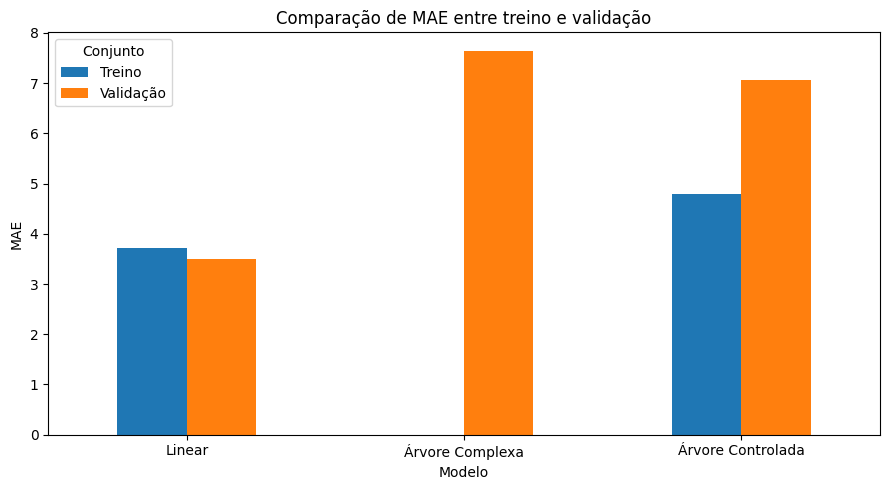

In [45]:
# Gere o gráfico de MAE aqui
ax = res_mae.plot(kind='bar', rot=0, figsize=(9,5), title='Comparação de MAE entre treino e validação')
ax.set_ylabel('MAE')
plt.tight_layout()
plt.show()

In [ ]:
# Repita o mesmo processo utilizando `res_rmse` para comparar o RMSE entre treino e validação.
# Defina o título como 'Comparação de RMSE entre treino e validação'.
# Utilize `ax.set_ylabel('RMSE')` para identificar o eixo Y.
# Utilize `plt.tight_layout()` e `plt.show()`.

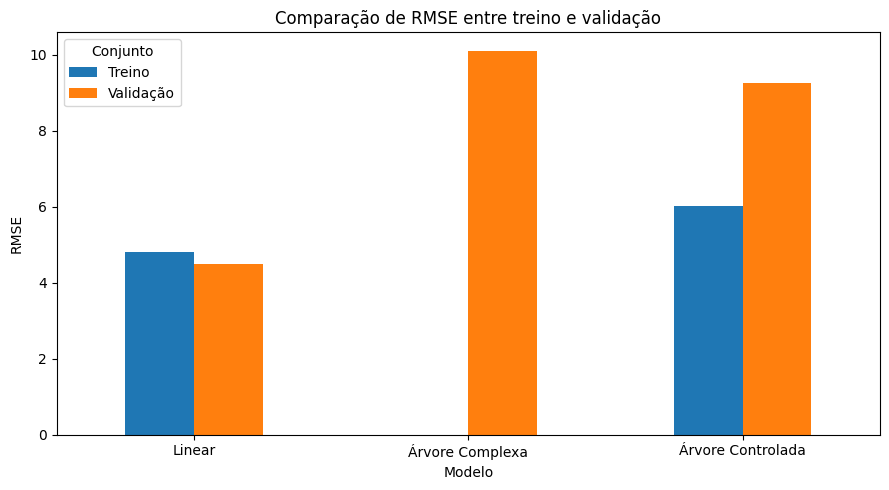

In [46]:
# Gere o gráfico de RMSE aqui
ax = res_rmse.plot(kind='bar', rot=0, figsize=(9,5), title='Comparação de RMSE entre treino e validação')
ax.set_ylabel('RMSE')
plt.tight_layout()
plt.show()

In [ ]:
# Repita o processo utilizando `res_r2` para comparar o R² entre treino e validação.
# Defina o título como 'Comparação de R² entre treino e validação'.
# Utilize `ax.set_ylabel('R²')` para identificar o eixo Y.
# Utilize `plt.tight_layout()` e `plt.show()`.

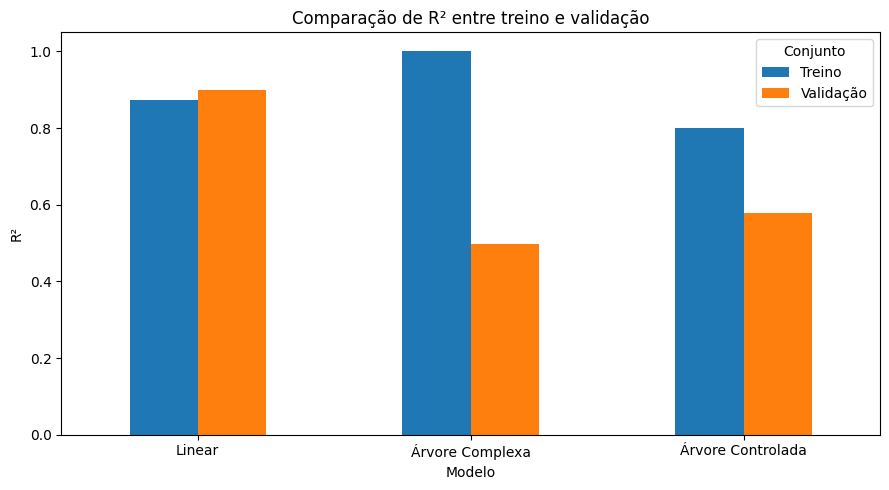

In [54]:
# Gere o gráfico de R² aqui
ax = res_r2.plot(kind='bar', rot=0, figsize=(9,5), title='Comparação de R² entre treino e validação')
ax.set_ylabel('R²')
plt.tight_layout()
plt.show()

## 13. Interpretação: underfitting, overfitting e generalização

Use os resultados para identificar:
- qual modelo parece simples demais;
- qual modelo parece ajustado demais ao treino;
- qual modelo parece mais equilibrado.


**Interpretação do aluno:**  
- Possível underfitting:  
- Possível overfitting:  
- Melhor generalização:  


## 14. Viés e variância

Relacione os modelos aos conceitos:
- alto viés;
- alta variância;
- equilíbrio entre ambos.


**Resposta do aluno:**  
- Alto viés:  
- Alta variância:  
- Melhor equilíbrio:  


## 15. Validação cruzada (k-fold)

>Aplique validação cruzada com 5 folds para os três modelos.

* Agora vamos verificar se o comportamento observado em uma única divisão também aparece quando repetimos a avaliação em múltiplos folds.

* Vamos verificar se o desempenho dos modelos é consistente em diferentes divisões dos dados.


In [ ]:
# Crie um objeto de validação cruzada usando `KFold`.
# Utilize `n_splits=5` para dividir os dados em 5 partes (folds).
# Utilize `shuffle=True` para embaralhar os registros antes da divisão.
# Utilize `random_state=42` para que a divisão seja reproduzível.
# Armazene o resultado na variável `kf`.

# Aplique a validação cruzada ao modelo de Regressão Linear usando `cross_val_score()`.
# Utilize o modelo `modelo_linear`.
# Utilize os dados `X_temp` como variáveis de entrada.
# Utilize `y_temp` como variável alvo.
# Informe `cv=kf` para utilizar a divisão criada anteriormente.
# Utilize `scoring='r2'` para avaliar o modelo utilizando o R².
# Armazene os 5 resultados na variável `cv_linear`.

# Repita a validação cruzada para a Árvore de Decisão Complexa.
# Utilize `modelo_arvore_complexa`.
# Utilize `X_temp`, `y_temp`, `cv=kf` e `scoring='r2'`.
# Armazene os resultados na variável `cv_arvore_complexa`.

# Repita a validação cruzada para a Árvore de Decisão Controlada.
# Utilize `modelo_arvore_controlada`.
# Utilize `X_temp`, `y_temp`, `cv=kf` e `scoring='r2'`.
# Armazene os resultados na variável `cv_arvore_controlada`.

# Exiba os 5 valores de R² obtidos pela Regressão Linear.
# Utilize `print()`.
# Exiba o texto `'R² - Linear:'`.
# Depois, mostre a variável `cv_linear`.
# Utilize `cv_linear.mean()` para calcular a média dos 5 valores de R².
# Utilize `.round(4)` para arredondar a média para 4 casas decimais.

# Exiba os 5 valores de R² obtidos pela Árvore de Decisão Complexa.
# Utilize `print()`.
# Exiba o texto `'R² - Árvore Complexa:'`.
# Depois, mostre a variável `cv_arvore_complexa`.
# Utilize `cv_arvore_complexa.mean()` para calcular a média dos resultados.
# Utilize `.round(4)` para arredondar a média para 4 casas decimais.

# Exiba os 5 valores de R² obtidos pela Árvore de Decisão Controlada.
# Utilize `print()`.
# Exiba o texto `'R² - Árvore Controlada:'`.
# Depois, mostre a variável `cv_arvore_controlada`.
# Utilize `cv_arvore_controlada.mean()` para calcular a média dos resultados.
# Utilize `.round(4)` para arredondar a média para 4 casas decimais.

In [55]:
# Complete aqui
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_linear = cross_val_score(modelo_linear, X_temp, y_temp, cv=kf, scoring='r2')
cv_arvore_complexa =  cross_val_score(modelo_arvore_complexa, X_temp, y_temp, cv=kf, scoring='r2')
cv_arvore_controlada =  cross_val_score(modelo_arvore_controlada, X_temp, y_temp, cv=kf, scoring='r2')

print('R² - Linear:', cv_linear, ' | média =', cv_linear.mean().round(4))
print('R² - Árvore Complexa:', cv_arvore_complexa, ' | média =', cv_arvore_complexa.mean().round(4))
print('R² - Árvore Controlada:', cv_arvore_controlada, ' | média =', cv_arvore_controlada.mean().round(4))



R² - Linear: [0.89343797 0.87445245 0.85028666 0.85210598 0.82894282]  | média = 0.8598
R² - Árvore Complexa: [0.29183209 0.48138866 0.43933071 0.55435843 0.61326068]  | média = 0.476
R² - Árvore Controlada: [0.4548478  0.63879246 0.4362074  0.50103111 0.64455785]  | média = 0.5351


In [ ]:
# Calcular o MAE usando validação cruzada com 5 folds para a Regressão Linear.
# Use a função cross_val_score().
# Passe como primeiro parâmetro o modelo treinado: modelo_linear.
# Passe X_temp como os dados de entrada e y_temp como os valores reais.
# Use cv=kf para informar que será utilizada a configuração de validação cruzada definida anteriormente.
# Use scoring='neg_mean_absolute_error' para calcular o MAE.
# O scikit-learn retorna essa métrica com valores negativos, por isso multiplique o resultado por (-1)
# para transformar os valores em MAE positivo.
# Armazene o resultado na variável cv_linear_mae.

# Calcular o MAE usando validação cruzada para a Árvore Complexa.
# Use novamente a função cross_val_score().
# Passe modelo_arvore_complexa como modelo.
# Passe X_temp e y_temp como os dados utilizados na validação cruzada.
# Use cv=kf para utilizar os 5 folds.
# Use scoring='neg_mean_absolute_error'.
# Multiplique o resultado por (-1) para obter o MAE positivo.
# Armazene o resultado na variável cv_arvore_complexa_mae.

# Calcular o MAE usando validação cruzada para a Árvore Controlada.
# Use cross_val_score() com modelo_arvore_controlada.
# Passe X_temp e y_temp como os dados.
# Use cv=kf para utilizar os 5 folds.
# Use scoring='neg_mean_absolute_error'.
# Multiplique o resultado por (-1) para converter os valores negativos em MAE positivo.
# Armazene o resultado na variável cv_arvore_controlada_mae.

# Exibir os 5 valores de MAE obtidos para a Regressão Linear.
# Use print().
# Mostre também a média dos 5 valores usando o método .mean().
# Use o método .round(4) para arredondar a média para 4 casas decimais.
# Use o texto 'MAE - Linear:' antes dos resultados.

# Exibir os 5 valores de MAE obtidos para a Árvore Complexa.
# Mostre também a média usando .mean().round(4).
# Use o texto 'MAE - Árvore Complexa:' antes dos resultados.

# Exibir os 5 valores de MAE obtidos para a Árvore Controlada.
# Mostre também a média usando .mean().round(4).
# Use o texto 'MAE - Árvore Controlada:' antes dos resultados.

In [59]:
cv_linear_mae = cross_val_score(modelo_linear, X_temp, y_temp, cv=kf, scoring='neg_mean_absolute_error') *(-1)
cv_arvore_complexa_mae = cross_val_score(modelo_arvore_complexa, X_temp, y_temp, cv=kf, scoring='neg_mean_absolute_error') *(-1)
cv_arvore_controlada_mae = cross_val_score(modelo_arvore_controlada, X_temp, y_temp, cv=kf, scoring='neg_mean_absolute_error')* (-1)

print('\nMAE - Linear:', cv_linear_mae, ' | média =', cv_linear_mae.mean().round(4))
print('MAE - Árvore Complexa:', cv_arvore_complexa_mae, ' | média =', cv_arvore_complexa_mae.mean().round(4))
print('MAE - Árvore Controlada:', cv_arvore_controlada_mae, ' | média =', cv_arvore_controlada_mae.mean().round(4))


MAE - Linear: [3.68399161 3.6623984  3.48236523 4.20743135 4.74940251]  | média = 3.9571
MAE - Árvore Complexa: [8.54153846 7.16019608 7.45137255 7.52745098 7.06862745]  | média = 7.5498
MAE - Árvore Controlada: [7.41572816 6.30379669 7.73156733 7.97745413 6.87355971]  | média = 7.2604


In [ ]:
# Calcular o RMSE usando validação cruzada com 5 folds para a Regressão Linear.
# Use a função cross_val_score().
# Passe modelo_linear como o modelo que será avaliado.
# Passe X_temp e y_temp como os dados utilizados na validação cruzada.
# Use cv=kf para utilizar os 5 folds definidos anteriormente.
# Use scoring='neg_root_mean_squared_error' para calcular o RMSE.
# O scikit-learn retorna essa métrica com valor negativo.
# Multiplique o resultado por (-1) para transformar os valores em RMSE positivo.
# Armazene os resultados na variável cv_linear_rsme.

# Calcular o RMSE usando validação cruzada para a Árvore Complexa.
# Use cross_val_score() com modelo_arvore_complexa.
# Passe X_temp e y_temp como os dados.
# Use cv=kf para utilizar os 5 folds.
# Use scoring='neg_root_mean_squared_error'.
# Multiplique o resultado por (-1) para obter o RMSE positivo.
# Armazene os resultados na variável cv_arvore_complexa_rsme.

# Calcular o RMSE usando validação cruzada para a Árvore Controlada.
# Use cross_val_score() com modelo_arvore_controlada.
# Passe X_temp e y_temp como os dados.
# Use cv=kf para utilizar os 5 folds.
# Use scoring='neg_root_mean_squared_error'.
# Multiplique o resultado por (-1) para obter o RMSE positivo.
# Armazene os resultados na variável cv_arvore_controlada_rsme.

# Exibir os 5 valores de RMSE obtidos para a Regressão Linear.
# Use print().
# Mostre também a média dos 5 valores usando o método .mean().
# Use .round(4) para arredondar a média para 4 casas decimais.
# Use o texto 'RMSE - Linear:' antes dos resultados.

# Exibir os 5 valores de RMSE obtidos para a Árvore Complexa.
# Mostre também a média usando .mean().round(4).
# Use o texto 'RMSE - Árvore Complexa:' antes dos resultados.

# Exibir os 5 valores de RMSE obtidos para a Árvore Controlada.
# Mostre também a média usando .mean().round(4).
# Use o texto 'RMSE - Árvore Controlada:' antes dos resultados.

In [58]:
cv_linear_rsme = cross_val_score(modelo_linear, X_temp, y_temp, cv=kf, scoring='neg_root_mean_squared_error') *(-1)
cv_arvore_complexa_rsme = cross_val_score(modelo_arvore_complexa, X_temp, y_temp, cv=kf, scoring='neg_root_mean_squared_error')*(-1)
cv_arvore_controlada_rsme = cross_val_score(modelo_arvore_controlada, X_temp, y_temp, cv=kf, scoring='neg_root_mean_squared_error')*(-1)

print('\nRMSE - Linear:', cv_linear_rsme, ' | média =', cv_linear_rsme.mean().round(4))
print('RMSE - Árvore Complexa:', cv_arvore_complexa_rsme, ' | média =', cv_arvore_complexa_rsme.mean().round(4))
print('RMSE - Árvore Controlada:', cv_arvore_controlada_rsme, ' | média =', cv_arvore_controlada_rsme.mean().round(4))


RMSE - Linear: [4.60596389 4.5968556  4.75446868 5.44979296 6.03240921]  | média = 5.0879
RMSE - Árvore Complexa: [11.87373653  9.3428149   9.20079025  9.4601397   9.07045992]  | média = 9.7896
RMSE - Árvore Controlada: [10.41785176  7.79713664  9.22638202 10.01016961  8.6957012 ]  | média = 9.2294


```python
kf = KFold(n_splits=5, shuffle=True, random_state=42)
```

Essa linha cria uma estratégia de:

> **Validação Cruzada (K-Fold) com 5 divisões.**

---

### `n_splits=5`

Divide o conjunto de dados em:

* 5 partes (folds).

Em cada rodada:

* 4 partes são usadas para treino
* 1 parte é usada para validação

Até que todas as partes tenham sido usadas como validação uma vez.

---

### `shuffle=True`

Embaralha os registros antes da divisão.

Isso evita que:

* dados ordenados
* ou agrupados por categoria

influenciem o resultado.

---

### `random_state=42`

Define uma semente fixa para o embaralhamento.

Assim:

* a divisão será sempre a mesma
* os resultados poderão ser reproduzidos.

---

### Resultado

> Cria uma validação cruzada que embaralha os dados e os divide em 5 partes para testar o modelo várias vezes de forma mais confiável.


A média refere-se aos:

> **5 valores de R² obtidos nas 5 rodadas do K-Fold.**

---

# O que acontece aqui?

```python
cv_linear = cross_val_score(
    modelo_linear,
    X_temp,
    y_temp,
    cv=kf,
    scoring='r2'
)
```

O `cross_val_score()`:

1. divide os dados em 5 partes
2. treina o modelo 5 vezes
3. calcula um valor de R² em cada rodada

---

# Exemplo

Imagine que os resultados sejam:

```python
[0.88, 0.91, 0.86, 0.89, 0.90]
```

Cada número representa:

> o R² obtido em uma das validações do K-Fold.

---

# O que faz o `.mean()`?

```python
cv_linear.mean()
```

Calcula:

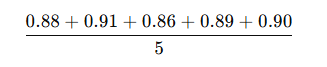

Resultado:

```python
0.888
```

---

# Interpretação

Quando você imprime:

```python
print('R² - Linear:', cv_linear, ' | média =', cv_linear.mean().round(4))
```

está mostrando:

* os R² individuais de cada fold
* e a média geral de desempenho do modelo

---

# Uma frase simples seria:

> "O modelo foi testado 5 vezes em conjuntos diferentes de validação. A média representa o desempenho médio do modelo considerando todas as rodadas da validação cruzada."

Ou ainda:

> "A média é o R² médio obtido pelo modelo ao longo das 5 execuções do K-Fold."


## 16. Visualização da validação cruzada

Monte uma tabela com os folds e crie um gráfico comparando os três modelos.


In [ ]:
# Criar um DataFrame chamado cv_df usando a função pd.DataFrame().
# Esse DataFrame será utilizado para organizar os resultados do R²
# obtidos nos 5 folds da validação cruzada.

# Criar a coluna 'Fold' com os valores 1, 2, 3, 4 e 5,
# representando os cinco folds utilizados pelo KFold.

# Criar a coluna 'Linear' utilizando os valores armazenados
# na variável cv_linear.

# Criar a coluna 'Árvore Complexa'
# utilizando os valores armazenados na variável cv_arvore_complexa.

# Criar a coluna 'Árvore Controlada'
# utilizando os valores armazenados na variável cv_arvore_controlada.

# Usar o parâmetro index= para criar um índice personalizado.
# Neste exercício, o índice será formado por cinco valores 'R²',
# um para cada fold.

# Os cinco valores do índice devem ser escritos dentro de uma lista:
# ['R²', 'R²', 'R²', 'R²', 'R²'].

# Atenção:
# As colunas devem ser separadas por vírgulas.
# Cada coluna deve possuir exatamente 5 valores,
# correspondentes aos 5 folds da validação cruzada.

# O resultado será uma tabela contendo:
# Fold | Linear | Árvore Complexa | Árvore Controlada
# e cada linha representará um dos 5 folds avaliados pelo R².
#exiba cv_df

In [57]:
# Complete aqui
cv_df = pd.DataFrame({
    'Fold': [1, 2, 3, 4, 5],
    'Linear': cv_linear,
    'Árvore Complexa': cv_arvore_complexa,
    'Árvore Controlada': cv_arvore_controlada
}, index=['R²', 'R²', 'R²', 'R²', 'R²'])

cv_df

,Fold,Linear,Árvore Complexa,Árvore Controlada
R²,1,0.893438,0.291832,0.454848
R²,2,0.874452,0.481389,0.638792
R²,3,0.850287,0.439331,0.436207
R²,4,0.852106,0.554358,0.501031
R²,5,0.828943,0.613261,0.644558


In [ ]:
# Criar um DataFrame chamado cv_df_mae usando a função pd.DataFrame().
# Esse DataFrame será utilizado para organizar os resultados do MAE
# obtidos nos 5 folds da validação cruzada.

# Criar a coluna 'Fold' com os valores 1, 2, 3, 4 e 5,
# representando os cinco folds utilizados pelo KFold.

# Criar a coluna 'Linear' utilizando os valores armazenados
# na variável cv_linear_mae.

# Criar uma coluna chamada 'Árvore Complexa'
# utilizando os valores armazenados na variável cv_arvore_complexa_mae.

# Criar uma coluna chamada 'Árvore Controlada'
# utilizando os valores armazenados na variável cv_arvore_controlada_mae.

# Usar o parâmetro index= para criar um índice personalizado.
# Neste exercício, o índice será formado por cinco valores 'MAE',
# um para cada fold.

# Os cinco valores do índice devem ser escritos dentro de uma lista:
# ['MAE', 'MAE', 'MAE', 'MAE', 'MAE'].

# Atenção:
# As colunas devem ser separadas por vírgulas.
# Cada coluna deve possuir exatamente 5 valores,
# para corresponder aos 5 folds da validação cruzada.

# O resultado será uma tabela contendo:
# Fold | Linear | Árvore Complexa | Árvore Controlada
# e cada linha representará um dos 5 folds.
# exiba cv_df_mae

In [60]:
cv_df_mae = pd.DataFrame({
    'Fold': [1, 2, 3, 4, 5],
    'Linear': cv_linear_mae,
    'Árvore Complexa': cv_arvore_complexa_mae,
    'Árvore Controlada': cv_arvore_controlada_mae
}, index=['MAE', 'MAE', 'MAE', 'MAE', 'MAE'])

cv_df_mae

,Fold,Linear,Árvore Complexa,Árvore Controlada
MAE,1,3.683992,8.541538,7.415728
MAE,2,3.662398,7.160196,6.303797
MAE,3,3.482365,7.451373,7.731567
MAE,4,4.207431,7.527451,7.977454
MAE,5,4.749403,7.068627,6.873560


In [ ]:
# Criar um DataFrame chamado cv_df_rsme usando a função pd.DataFrame().
# Esse DataFrame será utilizado para organizar os resultados do RMSE
# obtidos nos 5 folds da validação cruzada.

# Criar a coluna 'Fold' com os valores 1, 2, 3, 4 e 5,
# representando os cinco folds utilizados pelo KFold.

# Criar a coluna 'Linear' utilizando os valores armazenados
# na variável cv_linear_rsme.

# Criar a coluna 'Árvore Complexa'
# utilizando os valores armazenados na variável cv_arvore_complexa_rsme.

# Criar a coluna 'Árvore Controlada'
# utilizando os valores armazenados na variável cv_arvore_controlada_rsme.

# Usar o parâmetro index= para criar um índice personalizado.
# Neste exercício, o índice será formado por cinco valores 'RSME',
# um para cada fold.
# Observação: o nome correto da métrica é RMSE (e não RSME),
# mas aqui devemos manter 'RSME' exatamente como está no código.

# Os cinco valores do índice devem ser escritos dentro de uma lista:
# ['RSME', 'RSME', 'RSME', 'RSME', 'RSME'].

# Atenção:
# As colunas devem ser separadas por vírgulas.
# Cada coluna deve possuir exatamente 5 valores,
# correspondentes aos 5 folds da validação cruzada.

# O resultado será uma tabela contendo:
# Fold | Linear | Árvore Complexa | Árvore Controlada
# e cada linha representará um dos 5 folds avaliados pelo RMSE.

# exiba cv_df_rsme

In [61]:
cv_df_rsme = pd.DataFrame({
    'Fold': [1, 2, 3, 4, 5],
    'Linear': cv_linear_rsme,
    'Árvore Complexa': cv_arvore_complexa_rsme,
    'Árvore Controlada': cv_arvore_controlada_rsme
}, index=['RSME', 'RSME', 'RSME', 'RSME', 'RSME'])

cv_df_rsme

,Fold,Linear,Árvore Complexa,Árvore Controlada
RSME,1,4.605964,11.873737,10.417852
RSME,2,4.596856,9.342815,7.797137
RSME,3,4.754469,9.200790,9.226382
RSME,4,5.449793,9.460140,10.010170
RSME,5,6.032409,9.070460,8.695701


In [ ]:
# Crie uma nova figura usando `plt.figure()`.
# Defina o tamanho da figura com `figsize=(9,5)`.

# Crie uma linha para os resultados da Regressão Linear usando `plt.plot()`.
# Utilize `cv_df['Fold']` no eixo X.
# Utilize `cv_df['Linear']` no eixo Y.
# Use `marker='o'` para mostrar cada resultado como um ponto.
# Use `label='Linear'` para identificar a linha na legenda.

# Crie uma linha para os resultados da Árvore de Decisão Complexa.
# Utilize `cv_df['Fold']` no eixo X.
# Utilize `cv_df['Árvore Complexa']` no eixo Y.
# Use `marker='o'`.
# Use `label='Árvore Complexa'`.

# Crie uma linha para os resultados da Árvore de Decisão Controlada.
# Utilize `cv_df['Fold']` no eixo X.
# Utilize `cv_df['Árvore Controlada']` no eixo Y.
# Use `marker='o'`.
# Use `label='Árvore Controlada'`.

# Defina o título do gráfico usando `plt.title()`.
# Utilize o título: 'R² por fold na validação cruzada'.

# Defina o nome do eixo X usando `plt.xlabel()`.
# Utilize: 'Fold'.

# Defina o nome do eixo Y usando `plt.ylabel()`.
# Utilize: 'R²'.

# Exiba a legenda utilizando `plt.legend()`.
# A legenda mostrará o nome de cada um dos três modelos.

# Ajuste automaticamente o espaço do gráfico utilizando `plt.tight_layout()`.

# Exiba o gráfico utilizando `plt.show()`.

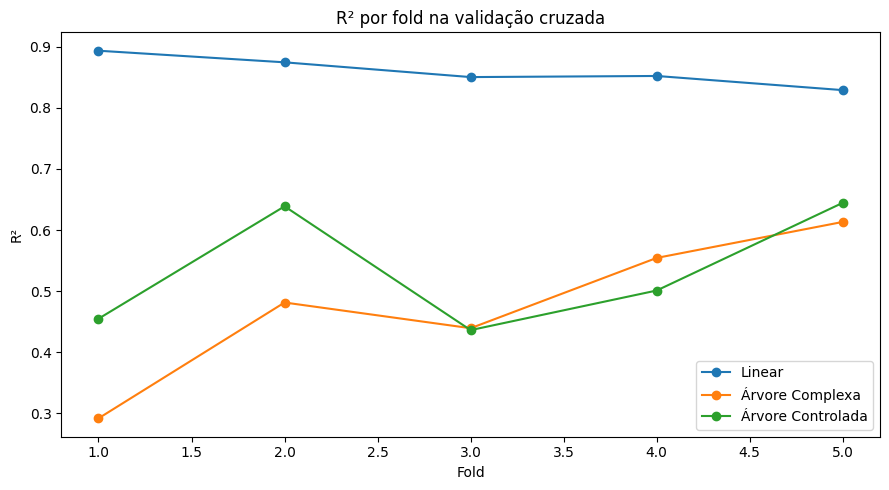

In [66]:
# Gere o gráfico aqui
plt.figure(figsize=(9,5))
plt.plot(cv_df['Fold'], cv_df['Linear'], marker='o', label='Linear')
plt.plot(cv_df['Fold'], cv_df['Árvore Complexa'], marker='o', label='Árvore Complexa')
plt.plot(cv_df['Fold'], cv_df['Árvore Controlada'], marker='o', label='Árvore Controlada')
plt.title('R² por fold na validação cruzada')
plt.xlabel('Fold')
plt.ylabel('R²')
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Criar uma figura usando plt.figure() com largura de 9 e altura de 5.
# O parâmetro figsize=(9,5) define o tamanho do gráfico.

# Criar uma linha para o modelo Linear usando plt.plot().
# No eixo X, utilizar cv_df_rsme['Fold'] para representar os folds.
# No eixo Y, utilizar cv_df_rsme['Linear'] para representar os valores de RMSE.
# Usar marker='o' para mostrar um círculo em cada ponto.
# Usar label='Linear' para identificar a linha na legenda.

# Criar uma segunda linha para a Árvore Complexa usando plt.plot().
# No eixo X, utilizar cv_df_rsme['Fold'].
# No eixo Y, utilizar cv_df_rsme['Árvore Complexa'].
# Usar marker='o' para marcar cada ponto.
# Usar label='Árvore Complexa' para identificar a linha na legenda.

# Criar uma terceira linha para a Árvore Controlada usando plt.plot().
# No eixo X, utilizar cv_df_rsme['Fold'].
# No eixo Y, utilizar cv_df_rsme['Árvore Controlada'].
# Usar marker='o' para marcar cada ponto.
# Usar label='Árvore Controlada' para identificar a linha na legenda.

# Definir o título do gráfico usando plt.title().
# O título deve ser 'RSME por fold na validação cruzada'.

# Definir o nome do eixo X usando plt.xlabel().
# O texto deve ser 'Fold'.

# Usar plt.xticks() para mostrar somente os 5 folds no eixo X.
# Utilizar range(1, kf.n_splits + 1).
# kf.n_splits informa a quantidade de folds definida no KFold.
# O resultado será: 1, 2, 3, 4 e 5.

# Definir o nome do eixo Y usando plt.ylabel().
# O texto deve ser 'RSME'.

# Exibir a legenda utilizando plt.legend().
# A legenda identificará as três linhas do gráfico.

# Usar plt.tight_layout() para ajustar automaticamente os espaços
# e evitar que textos e rótulos fiquem cortados.

# Exibir o gráfico utilizando plt.show().

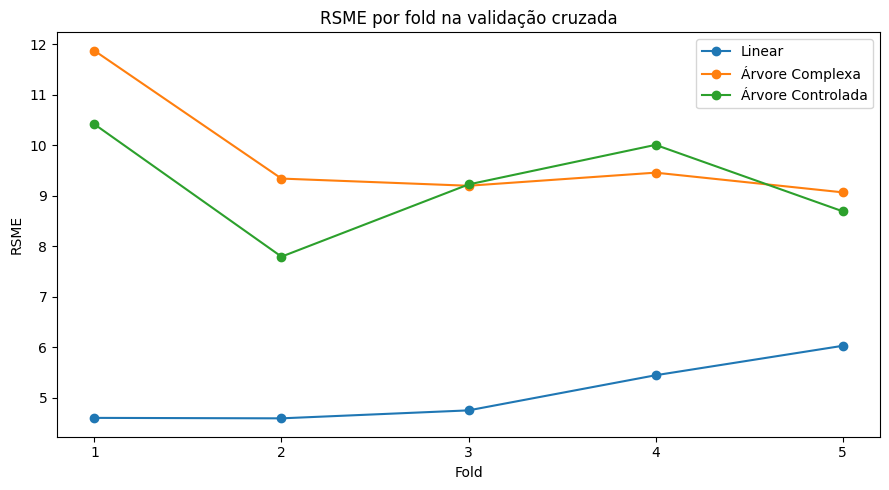

In [65]:
plt.figure(figsize=(9,5))
plt.plot(cv_df_rsme['Fold'], cv_df_rsme['Linear'], marker='o', label='Linear')
plt.plot(cv_df_rsme['Fold'], cv_df_rsme['Árvore Complexa'], marker='o', label='Árvore Complexa')
plt.plot(cv_df_rsme['Fold'], cv_df_rsme['Árvore Controlada'], marker='o', label='Árvore Controlada')
plt.title('RSME por fold na validação cruzada')
plt.xlabel('Fold')
plt.xticks(range(1, kf.n_splits + 1))
plt.ylabel('RSME')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Criar uma figura usando plt.figure() com largura de 9 e altura de 5.
# Usar figsize=(9,5) para definir o tamanho do gráfico.

# Criar uma linha para o modelo Linear usando plt.plot().
# No eixo X, utilizar cv_df_mae['Fold'] para representar os 5 folds.
# No eixo Y, utilizar cv_df_mae['Linear'] para representar os valores de MAE.
# Usar marker='o' para marcar cada ponto da linha.
# Usar label='Linear' para identificar o modelo na legenda.

# Criar uma segunda linha para o modelo Árvore Complexa usando plt.plot().
# No eixo X, utilizar cv_df_mae['Fold'].
# No eixo Y, utilizar cv_df_mae['Árvore Complexa'].
# Usar marker='o' para marcar cada ponto.
# Usar label='Árvore Complexa' para identificar o modelo na legenda.

# Criar uma terceira linha para o modelo Árvore Controlada usando plt.plot().
# No eixo X, utilizar cv_df_mae['Fold'].
# No eixo Y, utilizar cv_df_mae['Árvore Controlada'].
# Usar marker='o' para marcar cada ponto.
# Usar label='Árvore Controlada' para identificar o modelo na legenda.

# Definir o título do gráfico usando plt.title().
# O título deve ser 'MAE por fold na validação cruzada'.

# Definir o nome do eixo X usando plt.xlabel().
# O texto deve ser 'Fold'.

# Usar plt.xticks() para mostrar somente os 5 folds no eixo X.
# Utilizar range(1, kf.n_splits + 1).
# kf.n_splits representa a quantidade de folds definida no KFold.
# O eixo X deverá apresentar somente: 1, 2, 3, 4 e 5.

# Definir o nome do eixo Y usando plt.ylabel().
# O texto deve ser 'MAE'.

# Exibir a legenda utilizando plt.legend().
# A legenda identificará as três linhas: Linear,
# Árvore Complexa e Árvore Controlada.

# Usar plt.tight_layout() para ajustar automaticamente os espaços do gráfico.

# Exibir o gráfico na tela utilizando plt.show().

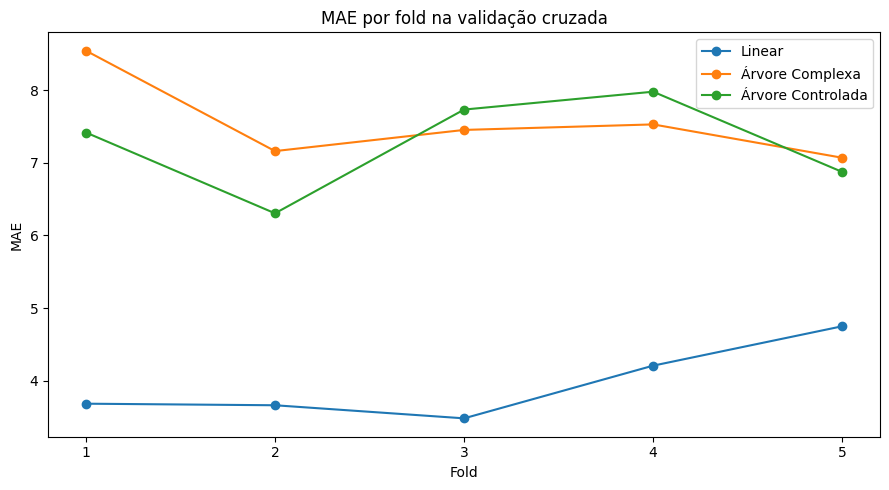

In [67]:
plt.figure(figsize=(9,5))
plt.plot(cv_df_mae['Fold'], cv_df_mae['Linear'], marker='o', label='Linear')
plt.plot(cv_df_mae['Fold'], cv_df_mae['Árvore Complexa'], marker='o', label='Árvore Complexa')
plt.plot(cv_df_mae['Fold'], cv_df_mae['Árvore Controlada'], marker='o', label='Árvore Controlada')
plt.title('MAE por fold na validação cruzada')
plt.xlabel('Fold')
plt.xticks(range(1, kf.n_splits + 1))
plt.ylabel('MAE')
plt.legend()
plt.tight_layout()
plt.show()

#Comparação

#1. Regressão Linear<br/>

Na divisão simples:

| Métrica  | Treino | Validação |
| -------- | -----: | --------: |
| **MAE**  |  3,708 |     3,498 |
| **RMSE** |  4,810 |     4,484 |
| **R²**   |  0,873 |     0,901 |
---
#Kfold

| Métrica  | Menor | Maior | Média aproximada |
| -------- | ----: | ----: | ---------------: |
| **MAE**  | 3,482 | 4,749 |        **3,957** |
| **RMSE** | 4,597 | 6,032 |        **5,088** |
| **R²**   | 0,829 | 0,893 |        **0,860** |


> ***Conclusão:*** o comportamento permanece relativamente consistente. Os erros continuam em uma faixa semelhante e o R² permanece elevado.


#2. Árvore Complexa

Na divisão simples:

| Métrica  | Treino |  Validação |
| -------- | -----: | ---------: |
| **MAE**  |  0,000 |  **7,629** |
| **RMSE** |  0,000 | **10,086** |
| **R²**   |  1,000 |  **0,498** |

---
#Kfold
| Métrica  | Menor |  Maior | Média aproximada |
| -------- | ----: | -----: | ---------------: |
| **MAE**  | 7,069 |  8,542 |        **7,550** |
| **RMSE** | 9,070 | 11,874 |        **9,790** |
| **R²**   | 0,292 |  0,613 |        **0,476** |

<br/>

***Conclusão:*** o comportamento observado na primeira divisão se mantém. A árvore apresenta erros consideravelmente maiores e R² menor nas diferentes divisões.

Além disso, a primeira divisão mostrou uma diferença enorme entre treino e validação:

* MAE: 0 → 7,629
* RMSE: 0 → 10,086
* R²: 1,00 → 0,498

Isso foi a evidência do overfitting.


#3. Árvore Controlada

Na divisão simples:

| Métrica  | Treino | Validação |
| -------- | -----: | --------: |
| **MAE**  |  4,789 |     7,056 |
| **RMSE** |  6,031 |     9,247 |
| **R²**   |  0,801 |     0,578 |

---
#Kfold
| Métrica  | Menor |  Maior | Média aproximada |
| -------- | ----: | -----: | ---------------: |
| **MAE**  | 6,304 |  7,977 |        **7,260** |
| **RMSE** | 7,797 | 10,418 |        **9,229** |
| **R²**   | 0,436 |  0,645 |        **0,535** |


<br/>

***Conclusão:*** também mantém aproximadamente o mesmo comportamento: erros maiores e R² inferior ao da Regressão Linear.

Portanto, antes de concluir que "o dataset está ruim", a pergunta correta para a próxima etapa seria:

> "Quais características dos dados estão fazendo os modelos terem dificuldade para generalizar?"

O que analisar?
* Correlação das variáveis com vazao_real_l_min
* Distribuição do alvo
* Outliers
* Relação entre cada variável e o alvo
* Valores extremos ou inconsistentes
* Quantidade de registros

## Como avaliar se houve boa generalização

Use treino, validação, teste e validação cruzada para decidir se o modelo generalizou bem.

### Referências práticas
- métricas relativamente próximas entre treino, validação e teste;
- **RMSE** não muito acima do **MAE**;
- **R²** como referência pedagógica:
  - abaixo de 0,50: fraco
  - entre 0,50 e 0,70: moderado
  - entre 0,70 e 0,85: bom
  - acima de 0,85: muito bom, desde que coerente entre os conjuntos

### Sinais importantes
- treino muito melhor que validação/teste → possível **overfitting**
- treino e validação ambos fracos → possível **underfitting**
- folds muito instáveis → possível falta de robustez


## 17. Avaliação final no conjunto de teste

Compare os três modelos no teste.


In [68]:
# Gerar as previsões do modelo Linear para os dados de teste.
# Usar o método predict() do modelo modelo_linear.
# Armazenar as previsões na variável pred_test_linear.
# Utilizar X_test como os dados de entrada para as previsões.

# Gerar as previsões da Árvore Complexa para os dados de teste.
# Usar o método predict() do modelo modelo_arvore_complexa.
# Armazenar as previsões na variável pred_test_arvore_complexa.
# Utilizar X_test como os dados de entrada.

# Gerar as previsões da Árvore Controlada para os dados de teste.
# Usar o método predict() do modelo modelo_arvore_controlada.
# Armazenar as previsões na variável pred_test_arvore_controlada.
# Utilizar X_test como os dados de entrada.

# Criar um DataFrame chamado teste_resultados usando pd.DataFrame().
# Esse DataFrame irá comparar o desempenho dos três modelos
# exclusivamente no conjunto de teste.

# Criar a coluna 'Modelo' com os nomes:
# 'Linear', 'Árvore Complexa' e 'Árvore Controlada'.

# Criar a coluna 'MAE_teste'.
# Para cada modelo, utilizar a função calcular_metricas().
# Passar y_test como primeiro argumento, representando os valores reais.
# Passar a previsão correspondente como segundo argumento.
# Utilizar [0] para selecionar o MAE retornado pela função.

# Para o modelo Linear, usar:
# calcular_metricas(y_test, pred_test_linear)[0]

# Para a Árvore Complexa, usar:
# calcular_metricas(y_test, pred_test_arvore_complexa)[0]

# Para a Árvore Controlada, usar:
# calcular_metricas(y_test, pred_test_arvore_controlada)[0]

# Criar a coluna 'RMSE_teste'.
# Utilizar novamente calcular_metricas() para cada modelo.
# Usar [1] para selecionar o RMSE retornado pela função.

# Para o modelo Linear, usar:
# calcular_metricas(y_test, pred_test_linear)[1]

# Para a Árvore Complexa, usar:
# calcular_metricas(y_test, pred_test_arvore_complexa)[1]

# Para a Árvore Controlada, usar:
# calcular_metricas(y_test, pred_test_arvore_controlada)[1]

# Criar a coluna 'R2_teste'.
# Utilizar novamente calcular_metricas() para cada modelo.
# Usar [2] para selecionar o R² retornado pela função.

# Para o modelo Linear, usar:
# calcular_metricas(y_test, pred_test_linear)[2]

# Para a Árvore Complexa, usar:
# calcular_metricas(y_test, pred_test_arvore_complexa)[2]

# Para a Árvore Controlada, usar:
# calcular_metricas(y_test, pred_test_arvore_controlada)[2]

# Depois de fechar o pd.DataFrame(), utilizar .round(4)
# para arredondar todos os valores numéricos para 4 casas decimais.

# Armazenar o resultado final na variável teste_resultados.

# Na última linha, escrever apenas teste_resultados
# para exibir a tabela com as métricas dos três modelos no conjunto de teste.

# Atenção:
# O conjunto X_test/y_test foi mantido separado durante todo o desenvolvimento.
# Agora ele será utilizado somente para a avaliação final dos modelos.

In [69]:
modelo_linear.fit(X_train, y_train)
modelo_arvore_complexa.fit(X_train, y_train)
modelo_arvore_controlada.fit(X_train, y_train)

pred_test_linear = modelo_linear.predict(X_test)
pred_test_arvore_complexa = modelo_arvore_complexa.predict(X_test)
pred_test_arvore_controlada = modelo_arvore_controlada.predict(X_test)

teste_resultados = pd.DataFrame({
    'Modelo': ['Linear', 'Árvore Complexa', 'Árvore Controlada'],
    'MAE_teste': [
        calcular_metricas(y_test, pred_test_linear)[0],
        calcular_metricas(y_test, pred_test_arvore_complexa)[0],
        calcular_metricas(y_test, pred_test_arvore_controlada)[0]
    ],
    'RMSE_teste': [
        calcular_metricas(y_test, pred_test_linear)[1],
        calcular_metricas(y_test, pred_test_arvore_complexa)[1],
        calcular_metricas(y_test, pred_test_arvore_controlada)[1]
    ],
    'R2_teste': [
        calcular_metricas(y_test, pred_test_linear)[2],
        calcular_metricas(y_test, pred_test_arvore_complexa)[2],
        calcular_metricas(y_test, pred_test_arvore_controlada)[2]
    ]
}).round(4)

teste_resultados

,Modelo,MAE_teste,RMSE_teste,R2_teste
0,Linear,3.5789,4.3775,0.8970
1,Árvore Complexa,6.4211,7.9619,0.6593
2,Árvore Controlada,6.2677,7.9279,0.6622


#Evidenciar os erros previstos/reais no modelo de divisão Simples, que nos orientaram nas metricas de MAE e RMSE

In [ ]:
# Criar uma função chamada mostrar_maiores_erros.
# A função deve receber os parâmetros y_real, y_pred e nome_modelo.
# y_real representa os valores reais.
# y_pred representa os valores previstos pelo modelo.
# nome_modelo representa o nome do modelo que será exibido no resultado.

# Criar um DataFrame chamado erros usando pd.DataFrame().
# Criar a coluna 'Real' com os valores de y_real.
# Criar a coluna 'Previsto' com os valores de y_pred.

# Criar a coluna 'Erro_Absoluto'.
# Subtrair 'Previsto' de 'Real'.
# Usar o método .abs() para obter o valor absoluto do erro.

# Criar a coluna 'Erro_Quadrado'.
# Subtrair 'Previsto' de 'Real'.
# Elevar o resultado ao quadrado usando ** 2.

# Ordenar o DataFrame erros usando o método .sort_values().
# Usar by='Erro_Absoluto' para ordenar pela coluna de erro absoluto.
# Usar ascending=False para colocar os maiores erros primeiro.

# Exibir uma mensagem com print().
# Usar uma f-string para inserir o conteúdo de nome_modelo.
# Usar '\n' antes do texto para criar uma quebra de linha.

# Exibir os 10 primeiros registros do DataFrame usando display().
# Usar o método .head(10) para selecionar os 10 maiores erros.

In [73]:
def mostrar_maiores_erros(y_real, y_pred, nome_modelo):

    erros = pd.DataFrame({
        'Real': y_real,
        'Previsto': y_pred
    })

    erros['Erro_Absoluto'] = (
        erros['Real'] - erros['Previsto']
    ).abs()

    erros['Erro_Quadrado'] = (
        erros['Real'] - erros['Previsto']
    ) ** 2

    erros = erros.sort_values(
        by='Erro_Absoluto',
        ascending=False
    )

    print(f'\nMaiores erros - {nome_modelo}')
    display(erros.head(10))

In [74]:
# Chamar a função mostrar_maiores_erros usando y_val como valores reais,
# pred_val_linear como valores previstos e 'Linear' como nome do modelo.

# Chamar a função mostrar_maiores_erros usando y_val como valores reais,
# pred_val_arvore_complexa como valores previstos e 'Árvore Complexa' como nome do modelo.

# Chamar a função mostrar_maiores_erros usando y_val como valores reais,
# pred_val_arvore_controlada como valores previstos e 'Árvore Controlada' como nome do modelo.

In [75]:
mostrar_maiores_erros(
    y_val,
    pred_val_linear,
    'Linear'
)

mostrar_maiores_erros(
    y_val,
    pred_val_arvore_complexa,
    'Árvore Complexa'
)

mostrar_maiores_erros(
    y_val,
    pred_val_arvore_controlada,
    'Árvore Controlada'
)


Maiores erros - Linear


,Real,Previsto,Erro_Absoluto,Erro_Quadrado
8,43.15,57.344765,14.194765,201.491361
189,46.91,57.703700,10.793700,116.503949
215,53.78,62.574546,8.794546,77.344043
264,64.58,56.103867,8.476133,71.844825
187,88.97,81.125587,7.844413,61.534816
201,55.89,48.832224,7.057776,49.812207
149,43.43,50.401982,6.971982,48.608538
116,54.02,60.834483,6.814483,46.437179
93,64.90,71.429620,6.529620,42.635936
171,50.65,44.199989,6.450011,41.602641



Maiores erros - Árvore Complexa


,Real,Previsto,Erro_Absoluto,Erro_Quadrado
266,13.32,58.61,45.29,2051.1841
53,59.00,39.88,19.12,365.5744
180,67.21,49.02,18.19,330.8761
256,59.38,76.52,17.14,293.7796
155,85.80,70.17,15.63,244.2969
49,66.42,80.43,14.01,196.2801
51,63.06,76.52,13.46,181.1716
201,55.89,43.01,12.88,165.8944
81,42.39,55.03,12.64,159.7696
272,73.87,61.32,12.55,157.5025



Maiores erros - Árvore Controlada


,Real,Previsto,Erro_Absoluto,Erro_Quadrado
266,13.32,46.671944,33.351944,1112.352198
180,67.21,46.671944,20.538056,421.811726
264,64.58,46.671944,17.908056,320.698454
155,85.80,69.115556,16.684444,278.370686
187,88.97,73.056667,15.913333,253.234178
233,71.34,56.415500,14.924500,222.740700
115,71.57,86.443000,14.873000,221.206129
106,73.05,86.443000,13.393000,179.372449
8,43.15,56.415500,13.265500,175.973490
61,99.13,86.443000,12.687000,160.959969


#Evidenciar Kfold que nos orientaram nas metricas de MAE e RMSE

In [76]:
from sklearn.base import clone

In [77]:
# Percorrer os 5 folds criados pelo KFold.
# Usar enumerate() para numerar cada fold.
# Usar kf.split(X_temp, y_temp) para obter os índices dos dados de treino e validação.
# Usar start=1 para iniciar a numeração dos folds em 1.

# Criar uma cópia do modelo Linear usando clone(modelo_linear).

# Usar os índices de treino para selecionar as linhas de X_temp com .iloc[indice_treino].
# Armazenar os dados na variável X_fold_treino.
# Usar os mesmos índices para selecionar y_temp e criar y_fold_treino.

# Usar os índices de validação para selecionar as linhas de X_temp com .iloc[indice_validacao].
# Armazenar os dados na variável X_fold_validacao.
# Usar os mesmos índices para selecionar y_temp e criar y_fold_validacao.

# Treinar o modelo usando .fit().
# Usar X_fold_treino como dados de entrada e y_fold_treino como valores reais.

# Fazer as previsões usando .predict().
# Usar X_fold_validacao como dados de entrada.
# Armazenar as previsões na variável predicoes.

# Criar um DataFrame chamado erros usando pd.DataFrame().
# Criar a coluna 'Real' com os valores de y_fold_validacao.
# Criar a coluna 'Previsto' com os valores armazenados em predicoes.

# Criar a coluna 'Erro_Absoluto'.
# Subtrair os valores da coluna 'Previsto' dos valores da coluna 'Real'.
# Usar o método .abs() para obter o valor absoluto do erro.

# Criar a coluna 'Erro_Quadrado'.
# Subtrair os valores da coluna 'Previsto' dos valores da coluna 'Real'.
# Elevar o resultado ao quadrado usando ** 2.

# Exibir o número do fold usando print() e uma f-string.
# Usar '\n===== FOLD {fold} =====' para mostrar o número do fold.

# Ordenar o DataFrame usando .sort_values().
# Usar by='Erro_Absoluto' para ordenar pelos erros absolutos.
# Usar ascending=False para colocar os maiores erros primeiro.
# Usar .head(5) para selecionar os 5 maiores erros.
# Usar display() para exibir os resultados no Colab.

# Exibir a quantidade total de linhas analisadas no fold.
# Usar len(erros) para contar as linhas do DataFrame.
# Inserir essa quantidade na mensagem usando uma f-string.

# Verificar se o fold atual é o primeiro usando if fold == 1.

# No primeiro fold, selecionar a coluna 'Erro_Quadrado' do DataFrame erros.
# Armazenar os valores na variável erros_quadrado.

# Calcular o MSE usando np.mean() sobre a variável erros_quadrado.
# Armazenar o resultado na variável mse.

# Calcular o RMSE usando np.sqrt() sobre a variável mse.
# Armazenar o resultado na variável rmse.

# Exibir o RMSE usando print() e uma f-string.
# Usar :.4f para mostrar o resultado com 4 casas decimais.

In [110]:
for fold, (indice_treino, indice_validacao) in enumerate(
    kf.split(X_temp, y_temp),
    start=1
):

    # Criar uma cópia do modelo
    modelo = clone(modelo_linear)

    # Separar os dados deste fold
    X_fold_treino = X_temp.iloc[indice_treino]
    y_fold_treino = y_temp.iloc[indice_treino]

    X_fold_validacao = X_temp.iloc[indice_validacao]
    y_fold_validacao = y_temp.iloc[indice_validacao]

    # Treinar o modelo
    modelo.fit(X_fold_treino, y_fold_treino)

    # Fazer previsões
    predicoes = modelo.predict(X_fold_validacao)

    # Criar tabela dos erros
    erros = pd.DataFrame({
        'Real': y_fold_validacao,
        'Previsto': predicoes
    })

    # Calcular erro absoluto
    erros['Erro_Absoluto'] = (
        erros['Real'] - erros['Previsto']
    ).abs()

    # Calcular erro ao quadrado
    erros['Erro_Quadrado'] = (
        erros['Real'] - erros['Previsto']
    ) ** 2

    # Mostrar os 5 maiores erros deste fold
    print(f'\n===== FOLD {fold} =====')
    display(
    erros.sort_values(
            by='Erro_Absoluto',
            ascending=False
        ).head(5)
    )
    print(f'\nTotal de Linha analisadas { len(erros) }')

    if fold == 1:
        erros_quadrado = erros['Erro_Quadrado']

# 1. Calcular o MSE (média dos erros quadrados) para o primeiro fold
mse = np.mean(erros_quadrado)

# 2. Calcular o RMSE (raiz quadrada do MSE)
rmse = np.sqrt(mse)

# Exibir resultados
print(f"\nResultados Finais baseados no Fold 1:")
print(f"MSE:  {mse:.6f}")
print(f"RMSE: {rmse:.6f}")





===== FOLD 1 =====


,Real,Previsto,Erro_Absoluto,Erro_Quadrado
8,43.15,57.410497,14.260497,203.361766
189,46.91,57.560066,10.650066,113.423915
187,88.97,81.137580,7.832420,61.346803
264,64.58,56.874165,7.705835,59.379895
93,64.90,71.855950,6.955950,48.385236



Total de Linha analisadas 52

===== FOLD 2 =====


,Real,Previsto,Erro_Absoluto,Erro_Quadrado
253,63.55,51.394113,12.155887,147.765578
30,55.83,65.306724,9.476724,89.808290
262,56.70,48.079356,8.620644,74.315497
225,58.09,49.718969,8.371031,70.074158
215,53.78,61.788224,8.008224,64.131654



Total de Linha analisadas 51

===== FOLD 3 =====


...


Total de Linha analisadas 51

===== FOLD 4 =====


,Real,Previsto,Erro_Absoluto,Erro_Quadrado
50,49.26,66.552599,17.292599,299.033988
303,48.04,32.813730,15.226270,231.839301
68,32.57,44.244708,11.674708,136.298801
111,68.90,60.413097,8.486903,72.027516
197,71.15,63.299837,7.850163,61.625058



Total de Linha analisadas 51

===== FOLD 5 =====


,Real,Previsto,Erro_Absoluto,Erro_Quadrado
199,43.43,56.896552,13.466552,181.348010
263,43.87,56.561107,12.691107,161.064207
121,52.21,64.419861,12.209861,149.080704
127,84.51,72.415713,12.094287,146.271787
16,56.16,44.106284,12.053716,145.292063



Total de Linha analisadas 51

Resultados Finais baseados no Fold 1:
MSE:  21.214903
RMSE: 4.605964


#Evidenciando Teste Final que nos orientaram nas metricas de MAE e RMSE

In [ ]:
# Criar um DataFrame chamado erros_teste usando pd.DataFrame().
# Criar a coluna 'Real' com os valores reais armazenados em y_test.
# Criar a coluna 'Previsto' com os valores previstos pelo modelo Linear,
# armazenados na variável pred_test_linear.

# Criar a coluna 'Erro_Absoluto'.
# Subtrair os valores da coluna 'Previsto' dos valores da coluna 'Real'.
# Usar o método .abs() para transformar os erros em valores absolutos.

# Criar a coluna 'Erro_Quadrado'.
# Subtrair os valores da coluna 'Previsto' dos valores da coluna 'Real'.
# Elevar o resultado ao quadrado usando ** 2.

# Ordenar o DataFrame erros_teste usando o método .sort_values().
# Usar by='Erro_Absoluto' para ordenar pela coluna de erro absoluto.
# Usar ascending=False para colocar os maiores erros primeiro.

# Exibir os 10 primeiros registros do DataFrame usando o método .head(10).
# Como o DataFrame foi ordenado do maior para o menor erro,
# os 10 registros exibidos serão os que possuem os maiores erros absolutos.

In [83]:
erros_teste = pd.DataFrame({
    'Real': y_test,
    'Previsto': pred_test_linear
})

erros_teste['Erro_Absoluto'] = (
    erros_teste['Real'] - erros_teste['Previsto']
).abs()

erros_teste['Erro_absoluto'] = (
    erros_teste['Real'] - erros_teste['Previsto']
) ** 2

erros_teste = erros_teste.sort_values(
    by='Erro_Absoluto',
    ascending=False
)

erros_teste.head(10)

,Real,Previsto,Erro_Absoluto,Erro_absoluto
60,88.93,98.468355,9.538355,90.980207
114,24.60,33.316456,8.716456,75.976602
46,50.06,58.173846,8.113846,65.834497
104,41.24,49.123203,7.883203,62.144895
186,62.97,55.456631,7.513369,56.450714
183,58.98,51.516411,7.463589,55.705166
77,61.03,53.655813,7.374187,54.378631
176,52.45,59.686585,7.236585,52.368158
300,54.20,61.422353,7.222353,52.162390
198,52.41,59.174366,6.764366,45.756649


#O gráfico do teste final mostra que:

>Regressão Linear: apresentou os menores erros (MAE e RMSE) e o maior R² (89,7%).<br/>
Árvore Complexa: apresentou erros maiores e R² de 65,9%.
Árvore Controlada: apresentou resultados semelhantes à complexa, com R² de 66,2%.

Conclusão: no conjunto de teste, a Regressão Linear apresentou o comportamento mais consistente e explicou a maior parte da variação da vazão

## 18. Interpretação final

Escreva:
- qual modelo mostrou sinais de underfitting;
- qual modelo mostrou sinais de overfitting;
- qual modelo foi mais confiável para generalização.


**Resposta do aluno:**  
- Underfitting:  
- Overfitting:  
- Melhor generalização:  


## 19. Exportação dos resultados

Salve as tabelas principais do experimento.


In [87]:
# Complete aqui
resultados.to_csv('resultados_treino_validacao.csv', index=False)
teste_resultados.to_csv('resultados_teste_final.csv', index=False)
cv_df.to_csv('resultados_validacao_cruzada.csv', index=False)

print('Arquivos exportados com sucesso de forma individual!')

Arquivos exportados com sucesso de forma individual!


## 20. Fechamento

Verifique se você:
- identificou sinais de underfitting e overfitting;
- relacionou os modelos a viés e variância;
- aplicou treino, validação, teste e validação cruzada com coerência.


#ESPAÇO IA GENEREATIVA

In [88]:
!pip install -q groq


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 2.2 MB/s eta 0:00:00


In [92]:
from groq import Groq
from google.colab import files
import base64

from google.colab import userdata
groq_api_key= userdata.get('groq.API')

client = Groq(api_key=groq_api_key)

def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(
            image_file.read()
        ).decode("utf-8")

In [93]:
base64_image = None

In [103]:
# arquivo = files.upload()
# nome_arquivo = list(arquivo.keys())[0]
# print("Arquivo selecionado:", nome_arquivo)
# base64_image = encode_image(nome_arquivo)

In [109]:
# prompt= input("Digite aqui sua pergunta===>")
# display(prompt)

In [106]:
prompt = f"""
Calcule o RMSE a partir destes valores de Erro_Quadrado:
{erros_quadrado}

Quantidade de valores: {len(erros_quadrado)}.
Mostre o MSE, o RMSE e o código Python utilizado.
"""
display(prompt)

'\nCalcule o RMSE a partir destes valores de Erro_Quadrado:\n101     21.027100\n158      1.393178\n280      2.481608\n218      0.057883\n93      48.385236\n59       2.397540\n116     39.416607\n272      2.415195\n288      3.762808\n81      18.379939\n219     33.723253\n269     21.620141\n182      5.909839\n256      6.006728\n247     14.449387\n125      0.825909\n233      0.683952\n206     18.902519\n267      1.261983\n115     11.579226\n163     26.872003\n242      1.250333\n35      21.286616\n266     11.759344\n26       0.091747\n313     31.992348\n171     39.062382\n61       2.822793\n122      5.262634\n162     22.304039\n310      6.956630\n8      203.361766\n64       0.135812\n44      19.713342\n40       5.867475\n305      1.765066\n153     10.193918\n292      0.016699\n201     39.352266\n43       3.869338\n53       0.033579\n49       9.517799\n264     59.379895\n13      36.011056\n134     10.483476\n307      0.210689\n189    113.423915\n187     61.346803\n252     18.519892\n191     

In [108]:

if base64_image is not None:
  response = client.chat.completions.create(
    model="qwen/qwen3.8-27b",
    messages=[
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": f"{prompt}"
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/png;base64,{base64_image}"
                    }
                }
            ]
        }
    ],
    temperature=0,

)
else:
  print("Nenhuma imagem foi selecionada.")
  response = client.chat.completions.create(
      model="qwen/qwen3.8-27b",
      messages=[
          {
              "role": "user",
              "content": [
                  {
                      "type": "text",
                      "text": f"{prompt}"
                  }
              ]
          }
      ],
      temperature=0,

  )

print(response.choices[0].message.content)

Nenhuma imagem foi selecionada.
Para calcular o **RMSE** (Root Mean Squared Error) a partir dos valores de **Erro_Quadrado** (que são os erros já elevados ao quadrado, ou seja, $e_i^2$), seguimos os seguintes passos:

1.  **MSE (Mean Squared Error)**: É a média dos valores de Erro_Quadrado.
    $$ \text{MSE} = \frac{\sum_{i=1}^{n} e_i^2}{n} $$
2.  **RMSE**: É a raiz quadrada do MSE.
    $$ \text{RMSE} = \sqrt{\text{MSE}} $$

### Cálculo Manual (Verificação)

Vamos somar todos os valores de `Erro_Quadrado` e dividir por 52.

Soma dos valores:
```
21.027100 + 1.393178 + 2.481608 + 0.057883 + 48.385236 + 2.397540 + 39.416607 + 2.415195 + 3.762808 + 18.379939 + 33.723253 + 21.620141 + 5.909839 + 6.006728 + 14.449387 + 0.825909 + 0.683952 + 18.902519 + 1.261983 + 11.579226 + 26.872003 + 1.250333 + 21.286616 + 11.759344 + 0.091747 + 31.992348 + 39.062382 + 2.822793 + 5.262634 + 22.304039 + 6.956630 + 203.361766 + 0.135812 + 19.713342 + 5.867475 + 1.765066 + 10.193918 + 0.016699 + 39.352266 +

## Síntese interpretativa dos resultados

A análise dos resultados obtidos evidencia, de forma aplicada, os conceitos de **generalização**, **overfitting**, **underfitting**, **viés** e **variância** no contexto da avaliação de modelos preditivos.

A **Regressão Linear** apresentou o comportamento mais consistente entre os modelos analisados, com métricas satisfatórias e relativamente estáveis nos conjuntos de **treino**, **validação** e **teste**, além de desempenho coerente na **validação cruzada**. Tal resultado indica adequada capacidade de generalização, demonstrando que o modelo conseguiu representar o padrão predominante dos dados sem excessivo ajuste ao conjunto de treinamento.

A **Árvore de Decisão Complexa**, por sua vez, apresentou desempenho extremamente elevado no conjunto de treino, porém com redução expressiva de desempenho nos conjuntos de validação, teste e folds da validação cruzada. Esse comportamento é característico de **overfitting**, situação em que o modelo se ajusta de forma excessiva aos dados utilizados no treinamento, comprometendo sua capacidade de generalização para novos dados.

A **Árvore de Decisão Controlada** apresentou desempenho intermediário, indicando que a restrição de complexidade contribuiu para reduzir o sobreajuste observado na árvore complexa. Ainda assim, seus resultados não superaram o equilíbrio apresentado pela regressão linear.

Dessa forma, os resultados reforçam que a avaliação de modelos não deve se restringir ao desempenho obtido no conjunto de treino. A análise conjunta de **treino**, **validação**, **teste** e **validação cruzada** é fundamental para verificar a robustez do modelo e sua aplicabilidade em situações reais, favorecendo a seleção de soluções com melhor equilíbrio entre ajuste, estabilidade e capacidade preditiva.